# San Luis Valley: Sentinel-1 scene search and HyP3 test batch (steps 1.4 and 1.5)

Run top to bottom. This works on native Windows. It needs only `asf_search`, `hyp3_sdk`, `shapely`, `pandas` and `rasterio`, so no WSL.

**What it does**
1. Finds Sentinel-1 IW SLC scenes over the valley and summarizes them by track and frame, so you can pick one (step 1.4).
2. Builds about 15 short-baseline test pairs, split between the growing season and the dormant season (step 1.5).
3. Submits them to HyP3 as 80 m InSAR jobs. **The default is a dry run.** Nothing is submitted or charged until you set `SUBMIT = True`.
4. Downloads finished products and prints a quick coherence look.

**Credentials:** the submit cell asks for an Earthdata **bearer token**, typed into a hidden prompt, and nothing is saved to disk. Generate one at urs.earthdata.nasa.gov: log in, open **Generate Token** in the profile menu, click Generate Token, then Show Token. Tokens last 60 days and you can hold two at a time. If you ever have a plain username and password, change `prompt="token"` to `prompt="password"`.

**Windows note:** keep `DATA_DIR` short. HyP3 product names are long, and a deep folder can hit Windows' default 260-character path limit.

In [25]:
# One-time install, in a terminal inside your conda environment (not in this notebook):
#   python -m pip install asf_search hyp3_sdk shapely pandas rasterio matplotlib

import re
from pathlib import Path

import numpy as np
import pandas as pd
import asf_search as asf
import hyp3_sdk
from shapely.geometry import box, shape

print("asf_search", asf.__version__, "| hyp3_sdk", hyp3_sdk.__version__)

asf_search 14.1.0 | hyp3_sdk 7.7.8


## Settings (edit these)

The area box is my rough estimate of the valley. After the well inventory (step 1.6), replace it with a box around your chosen wells. The 2022-2023 window avoids the period when Sentinel-1B was also acquiring (it failed in Dec 2021), so spacing should be a uniform 12 days. Confirm that in the output below.

In [27]:
# Area of interest as (west, south, east, north) in degrees. Approximate; verify.
AOI_BBOX = (-106.7, 37.2, -105.3, 38.4)

# Search window, and the two test seasons (growing = irrigated crops, dormant = bare ground)
WINDOW = ("2022-01-01", "2023-12-31")
GROW = ("2022-06-01", "2022-09-30")
DORMANT = ("2022-12-01", "2023-03-31")
N_GROW, N_DORM = 8, 7
MAX_BASELINE_DAYS = None        # None = use the chosen track's median spacing + 1 day. Or set a number

CREDITS_PER_PRODUCT = 10        # 80 m InSAR product, per ASF's HyP3 credits page
JOB_NAME = "slv_test"           # label used to find your jobs again later
SUBMIT = False                  # True = actually submit jobs and spend credits

DATA_DIR = Path("C:/insar")     # keep this path short on Windows

## Step 1.4: find scenes and pick one track

The table counts scenes by direction, relative orbit (`path`) and `frame`. HyP3 pairs two scenes from the same frame, so pick one row. `aoi_cover` is a rough fraction of your box that the frame covers. Prefer a row with high cover and the full scene count for your window.

In [20]:
aoi = box(*AOI_BBOX)

results = asf.geo_search(
    intersectsWith=aoi.wkt,
    platform=asf.PLATFORM.SENTINEL1,
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=asf.BEAMMODE.IW,
    start=WINDOW[0],
    end=WINDOW[1],
    maxResults=10000,
)
print(len(results), "scenes found")
if len(results) in (250, 500, 1000, 2000, 5000, 10000):
    print("WARNING: the count is a round number, so the search may have been cut off. Tell Claude this number.")


def to_row(p):
    pr = p.properties
    return {
        "scene": pr["sceneName"],
        "time": pd.to_datetime(pr["startTime"], utc=True),
        "direction": pr["flightDirection"],
        "path": pr["pathNumber"],
        "frame": pr["frameNumber"],
        "geom": shape(p.geometry),
    }


df = pd.DataFrame([to_row(p) for p in results])
df["aoi_cover"] = df["geom"].apply(lambda g: g.intersection(aoi).area / aoi.area)

summary = (
    df.groupby(["direction", "path", "frame"])
    .agg(scenes=("scene", "count"), first=("time", "min"), last=("time", "max"), aoi_cover=("aoi_cover", "mean"))
    .reset_index()
)
summary["aoi_cover"] = summary["aoi_cover"].round(2)
summary = summary.sort_values(["scenes", "aoi_cover"], ascending=False).reset_index(drop=True)
print("Pick a row near the top: you want the most scenes AND high aoi_cover.")
summary

436 scenes found
Pick a row near the top: you want the most scenes AND high aoi_cover.


,direction,path,frame,scenes,first,last,aoi_cover
0,DESCENDING,158,467,54,2022-03-08 13:02:14+00:00,2023-12-28 13:02:27+00:00,0.57
1,DESCENDING,158,462,54,2022-03-08 13:01:49+00:00,2023-12-28 13:02:02+00:00,0.01
2,DESCENDING,56,468,51,2022-03-25 13:10:36+00:00,2023-12-21 13:10:48+00:00,0.52
3,DESCENDING,56,463,43,2022-03-25 13:10:11+00:00,2023-11-03 13:10:25+00:00,0.59
4,ASCENDING,151,118,42,2022-07-30 01:02:03+00:00,2023-12-28 01:02:08+00:00,0.84
5,ASCENDING,151,123,42,2022-07-30 01:02:28+00:00,2023-12-28 01:02:33+00:00,0.27
6,ASCENDING,78,121,41,2022-07-25 00:54:08+00:00,2023-12-23 00:54:13+00:00,0.05
7,ASCENDING,78,116,41,2022-07-25 00:53:43+00:00,2023-12-23 00:53:48+00:00,0.00
8,ASCENDING,49,119,35,2022-10-27 01:10:24+00:00,2023-12-21 01:10:26+00:00,0.13
9,DESCENDING,56,464,8,2023-01-07 13:10:18+00:00,2023-12-21 13:10:23+00:00,0.59


In [21]:
# Pick one row from the table above and fill these in.
DIRECTION = "ASCENDING"   # "ASCENDING" or "DESCENDING"
PATH = 151        # relative orbit number
FRAME = 118       # frame number

if None in (DIRECTION, PATH, FRAME):
    raise ValueError("Set DIRECTION, PATH and FRAME above, using the table in the previous cell.")

sel = (
    df[(df.direction == DIRECTION) & (df.path == PATH) & (df.frame == FRAME)]
    .sort_values("time")
    .reset_index(drop=True)
)
spacing = sel["time"].diff().dt.total_seconds() / 86400
print(len(sel), "scenes |", sel.time.min().date(), "to", sel.time.max().date())
if len(sel) < 20:
    raise ValueError(f"This track has only {len(sel)} scenes in {WINDOW[0]} to {WINDOW[1]}. "
                     "Pick a row with more scenes from the table above, or send Claude the table.")
max_gap = MAX_BASELINE_DAYS or float(np.ceil(spacing.median())) + 1
print("median spacing (days):", round(spacing.median(), 1), "| shortest:", round(spacing.min(), 1),
      "| pairing scenes up to", max_gap, "days apart")
print("spacing counts (days -> number of gaps):", spacing.round().value_counts().sort_index().to_dict())

# For the credit budget on the Detailed Steps tab (full network, each scene paired with its next 3)
n_nb = 3
full_pairs = len(sel) * n_nb - n_nb * (n_nb + 1) // 2
print("Enter", len(sel), "as 'Scenes in the window'. Full batch would be about", full_pairs, "pairs =",
      full_pairs * CREDITS_PER_PRODUCT, "credits")

42 scenes | 2022-07-30 to 2023-12-28
median spacing (days): 12.0 | shortest: 12.0 | pairing scenes up to 13.0 days apart
spacing counts (days -> number of gaps): {12.0: 39, 24.0: 2}
Enter 42 as 'Scenes in the window'. Full batch would be about 120 pairs = 1200 credits


## Check frame coverage (do this before submitting)

HyP3 can only measure ground that every scene in your pairs covers. This cell intersects the footprints of all scenes in the chosen frame and tests whether your points of interest fall inside, with a rough distance to the edge. Points near the edge are risky, because processing clips to the common overlap.

Right now it tests three towns on the valley floor (approximate coordinates). After the well inventory (step 1.6), save your wells to a CSV with columns `lon`, `lat` and optionally `name`, and set `WELLS_CSV` to its path. Then change `DIRECTION`, `PATH` and `FRAME` and re-run to compare frames.

Ground covered by all 42 scenes: 84% of the AOI box
Alamosa        inside, about 75 km from the edge
Monte Vista    inside, about 61 km from the edge
Saguache       inside, about 10 km from the edge
USGS:USGS-374012105410401 inside, about 58 km from the edge
USGS:USGS-380325105250001 inside, about 23 km from the edge
USGS:USGS-380445105324301 inside, about 19 km from the edge
USGS:USGS-380514105281801 inside, about 20 km from the edge
USGS:USGS-380602105293501 inside, about 18 km from the edge
USGS:USGS-380652105341801 inside, about 16 km from the edge
USGS:USGS-380714105273801 inside, about 16 km from the edge
USGS:USGS-380732105304701 inside, about 15 km from the edge
USGS:USGS-380916105314301 inside, about 12 km from the edge
USGS:USGS-381120105341801 inside, about 8 km from the edge
USGS:USGS-381341105361801 inside, about 4 km from the edge  <-- close to edge
USGS:USGS-382220105412201 OUTSIDE the common footprint
DWR:31814      inside, about 58 km from the edge
DWR:6626       insid

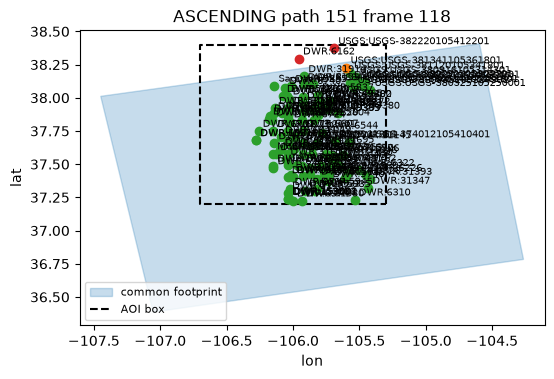

In [22]:
import matplotlib.pyplot as plt
from shapely.geometry import Point

PLACES = {"Alamosa": (-105.87, 37.47), "Monte Vista": (-106.15, 37.58), "Saguache": (-106.14, 38.09)}  # lon, lat, approximate
WELLS_CSV = "C:/insar/wells.csv"   # e.g. "C:/insar/wells.csv" with columns lon, lat and optionally name
EDGE_WARN_KM = 5   # warn if a point is closer to the footprint edge than this (rough)

common = sel["geom"].iloc[0]
for g in sel["geom"].iloc[1:]:
    common = common.intersection(g)
print(f"Ground covered by all {len(sel)} scenes: {common.intersection(aoi).area / aoi.area:.0%} of the AOI box")

pts = dict(PLACES)
if WELLS_CSV:
    w = pd.read_csv(WELLS_CSV)
    names = w["name"] if "name" in w.columns else w.index.astype(str)
    pts.update({str(n): (lo, la) for n, lo, la in zip(names, w["lon"], w["lat"])})



status = {}
for n, (lon, lat) in pts.items():
    p = Point(lon, lat)
    if common.contains(p):
        km = common.boundary.distance(p) * 100   # rough: 1 degree is about 90-110 km here
        status[n] = "inside" if km >= EDGE_WARN_KM else "NEAR EDGE"
        print(f"{n:<14} inside, about {km:.0f} km from the edge" + ("  <-- close to edge" if km < EDGE_WARN_KM else ""))
    else:
        status[n] = "OUTSIDE"
        print(f"{n:<14} OUTSIDE the common footprint")

print(pd.Series(status).value_counts())
print({k: [n for n, s in status.items() if s == k] for k in ("OUTSIDE", "NEAR EDGE")})

fig, ax = plt.subplots(figsize=(6, 6))
for poly in (common.geoms if hasattr(common, "geoms") else [common]):
    if not poly.is_empty:
        ax.fill(*poly.exterior.xy, alpha=0.25, color="tab:blue", label="common footprint")
ax.plot(*aoi.exterior.xy, "k--", label="AOI box")
colors = {"inside": "tab:green", "NEAR EDGE": "tab:orange", "OUTSIDE": "tab:red"}
for n, (lon, lat) in pts.items():
    ax.plot(lon, lat, "o", color=colors[status[n]])
    ax.annotate(n, (lon, lat), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("lon"); ax.set_ylabel("lat"); ax.set_aspect("equal")
ax.set_title(f"{DIRECTION} path {PATH} frame {FRAME}")
handles, labels = ax.get_legend_handles_labels()
ax.legend(dict(zip(labels, handles)).values(), dict(zip(labels, handles)).keys(), loc="lower left", fontsize=8)
plt.show()

## Step 1.5: build the test pairs

Pairs are consecutive scenes (about 12 days apart), spread evenly across each season. Comparing coherence between the two seasons tells you how much irrigation hurts. Check the pair table before submitting.

In [23]:
def consecutive_pairs(scenes, start, end, n, season):
    lo = pd.Timestamp(start, tz="UTC")
    hi = pd.Timestamp(end, tz="UTC") + pd.Timedelta(days=1)
    s = scenes[(scenes.time >= lo) & (scenes.time <= hi)].reset_index(drop=True)
    out = []
    for i in range(len(s) - 1):
        days = (s.time[i + 1] - s.time[i]).total_seconds() / 86400
        if days <= max_gap:
            out.append({"season": season, "ref": s.scene[i], "sec": s.scene[i + 1], "days": round(days, 1)})
    if len(out) < n:
        print(f"WARNING: only {len(out)} {season} pairs available (wanted {n}). "
              f"{len(s)} scenes in {start} to {end}; pairing up to {max_gap} days apart.")
    elif len(out) > n:
        idx = np.unique(np.linspace(0, len(out) - 1, n).round().astype(int))
        out = [out[i] for i in idx]
    return out


pairs = pd.DataFrame(
    consecutive_pairs(sel, *GROW, N_GROW, "growing") + consecutive_pairs(sel, *DORMANT, N_DORM, "dormant")
)
print(len(pairs), "pairs ->", len(pairs) * CREDITS_PER_PRODUCT, "credits")
pairs

10 pairs -> 100 credits


,season,ref,sec,days
0,growing,S1A_IW_SLC__1SDV_20220730T010203_20220730T0102...,S1A_IW_SLC__1SDV_20220811T010204_20220811T0102...,12.0
1,growing,S1A_IW_SLC__1SDV_20220904T010205_20220904T0102...,S1A_IW_SLC__1SDV_20220916T010205_20220916T0102...,12.0
2,growing,S1A_IW_SLC__1SDV_20220916T010205_20220916T0102...,S1A_IW_SLC__1SDV_20220928T010206_20220928T0102...,12.0
3,dormant,S1A_IW_SLC__1SDV_20221209T010205_20221209T0102...,S1A_IW_SLC__1SDV_20221221T010204_20221221T0102...,12.0
4,dormant,S1A_IW_SLC__1SDV_20221221T010204_20221221T0102...,S1A_IW_SLC__1SDV_20230102T010203_20230102T0102...,12.0
5,dormant,S1A_IW_SLC__1SDV_20230114T010202_20230114T0102...,S1A_IW_SLC__1SDV_20230126T010202_20230126T0102...,12.0
6,dormant,S1A_IW_SLC__1SDV_20230126T010202_20230126T0102...,S1A_IW_SLC__1SDV_20230207T010202_20230207T0102...,12.0
7,dormant,S1A_IW_SLC__1SDV_20230207T010202_20230207T0102...,S1A_IW_SLC__1SDV_20230219T010201_20230219T0102...,12.0
8,dormant,S1A_IW_SLC__1SDV_20230303T010202_20230303T0102...,S1A_IW_SLC__1SDV_20230315T010201_20230315T0102...,12.0
9,dormant,S1A_IW_SLC__1SDV_20230315T010201_20230315T0102...,S1A_IW_SLC__1SDV_20230327T010202_20230327T0102...,12.0


## Submit to HyP3

Dry run by default. When the pair table looks right, set `SUBMIT = True` in the settings cell and run this cell again. The job IDs are saved so you can find the jobs later. Includes the DEM and look vectors, which MintPy needs later.

In [28]:
DATA_DIR.mkdir(parents=True, exist_ok=True)

hyp3 = hyp3_sdk.HyP3(prompt="token")   # hidden prompt for your Earthdata bearer token
print("Credits remaining:", hyp3.check_credits())

if not SUBMIT:
    print("DRY RUN. Nothing submitted. Set SUBMIT = True in the settings cell to submit", len(pairs), "jobs.")
else:
    jobs = hyp3_sdk.Batch()
    for r in pairs.itertuples():
        jobs += hyp3.submit_insar_job(
            r.ref, r.sec, name=JOB_NAME, looks="20x4", include_look_vectors=True, include_dem=True
        )
    pairs.assign(job_id=[j.job_id for j in jobs]).to_csv(DATA_DIR / "test_pairs.csv", index=False)
    print("Submitted", len(jobs), "jobs. Job IDs saved to", DATA_DIR / "test_pairs.csv")

NASA Earthdata Login bearer token:  ········


Credits remaining: 7900
DRY RUN. Nothing submitted. Set SUBMIT = True in the settings cell to submit 10 jobs.


## Check status, then download

Re-run the status cell until jobs show as succeeded. Failed jobs are worth reading about before you resubmit, since a resubmit costs credits again.

In [29]:
FULL_SUBMIT = True     # set True to spend credits
rows = [{"ref": sel.scene[i], "sec": sel.scene[i + k], "days": (sel.time[i + k] - sel.time[i]).days}
        for i in range(len(sel)) for k in range(1, 4) if i + k < len(sel)]
full = pd.DataFrame(rows)
done = set(zip(pairs.ref, pairs.sec))
full = full[[(r, s) not in done for r, s in zip(full.ref, full.sec)]]
print(len(full), "new pairs ->", len(full) * CREDITS_PER_PRODUCT, "credits | credits left:", hyp3.check_credits())
print(full.days.value_counts().sort_index().to_dict())

if FULL_SUBMIT:
    jobs = hyp3_sdk.Batch()
    for r in full.itertuples():
        jobs += hyp3.submit_insar_job(r.ref, r.sec, name="slv_full", looks="20x4",
                                      include_look_vectors=True, include_dem=True)
    full.assign(job_id=[j.job_id for j in jobs]).to_csv(DATA_DIR / "full_pairs.csv", index=False)
    print("Submitted", len(jobs), "jobs")

110 new pairs -> 1100 credits | credits left: 7900
{11: 5, 12: 24, 23: 10, 24: 28, 35: 13, 36: 25, 47: 2, 48: 3}
Submitted 110 jobs


In [41]:
from collections import Counter

jobs = hyp3.find_jobs(name='slv_full')
print(len(jobs), "jobs:", dict(Counter(j.status_code for j in jobs)))

110 jobs: {'SUCCEEDED': 110}


In [48]:
ok = jobs.filter_jobs(succeeded=True, pending=False, running=False, failed=False, include_expired=False)
files = ok.download_files(DATA_DIR / "hyp3_full")
for f in files:
    hyp3_sdk.util.extract_zipped_product(f)
print("Downloaded and extracted", len(files), "products to", DATA_DIR / "hyp3_full")

SyntaxError: 'break' outside loop (2285512970.py, line 2)

## Quick look at coherence (whole scene, not yet well pixels)

This is only a sanity check that the products opened and that the growing and dormant seasons differ. The 0.3 threshold is illustrative. Step 1.7 replaces this with coherence at your well pixels and a noise estimate from stable ground. If no files are found, list the folder and check the file suffix.

In [43]:
import rasterio

rows = []
for tif in sorted((DATA_DIR / "hyp3_full").rglob("*_corr.tif")):
    m = re.search(r"_(\d{8})T\d{6}_(\d{8})T", tif.name)
    with rasterio.open(tif) as src:
        a = src.read(1).astype("float32")
    a = a[np.isfinite(a) & (a > 0)]
    rows.append({
        "ref": m.group(1) if m else tif.name,
        "sec": m.group(2) if m else "",
        "mean_coherence": round(float(a.mean()), 3),
        "frac_above_0.3": round(float((a > 0.3).mean()), 3),
    })

coh = pd.DataFrame(rows)
print(len(coh), "products")
coh

C:\Users\lilli\AppData\Local\Temp\ipykernel_59928\518344981.py:7: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a = src.read(1).astype("float32")


110 products


,ref,sec,mean_coherence,frac_above_0.3
0,20220730,20220904,0.603,0.822
1,20220730,20220916,0.650,0.880
2,20220811,20220904,0.715,0.907
3,20220811,20220916,0.779,0.962
4,20220811,20220928,0.839,0.978
...,...,...,...,...
105,20231122,20231216,0.697,0.890
106,20231122,20231228,0.664,0.854
107,20231204,20231216,0.712,0.913
108,20231204,20231228,0.639,0.843


In [44]:
from rasterio.warp import transform

wl = pd.read_csv(WELLS_CSV)
rows = []
for tif in sorted((DATA_DIR / "hyp3_full").rglob("*_corr.tif")):
    ref = re.search(r"_(\d{8})T\d{6}_(\d{8})T", tif.name).group(1)
    season = "growing" if ref[4:6] in ("06", "07", "08", "09") else "dormant"
    with rasterio.open(tif) as src:
        xs, ys = transform("EPSG:4326", src.crs, wl.lon.tolist(), wl.lat.tolist())
        for n, v in zip(wl.name, src.sample(zip(xs, ys))):
            rows.append((n, season, float(v[0])))
c = pd.DataFrame(rows, columns=["name", "season", "coh"]).replace({"coh": {0.0: np.nan}})
t = c.pivot_table(index="name", columns="season", values="coh", aggfunc="median").round(2)
print(t.describe().round(2)); print((t > 0.3).sum())

season  dormant  growing
count    117.00   117.00
mean       0.92     0.86
std        0.07     0.13
min        0.66     0.31
25%        0.89     0.81
50%        0.94     0.92
75%        0.97     0.95
max        0.99     0.98
season
dormant    117
growing    117
dtype: int64


In [45]:
ob = pd.read_csv(DATA_DIR / "well_obs.csv")
ob["name"] = ob.source + ":" + ob.id.astype(str)
sw = ob.groupby("name").depth_ft.agg(lambda s: (s.max() - s.min()) * 0.3048).rename("swing_m")
r = t.join(sw).join(wl.set_index("name")[["tier", "n_dates"]])
for sk in (1e-4, 1e-3):
    r[f"mm_sk{sk:g}"] = (r.swing_m * sk * 1000).round(2)
usable = (r.n_dates >= 18) | (r.tier == "daily")
print(r[usable].sort_values("swing_m", ascending=False).head(15).round(2))
print("usable wells with >=3 mm at Sk=1e-3:", (r[usable]["mm_sk0.001"] >= 3).sum(),
      "| at Sk=1e-4:", (r[usable]["mm_sk0.0001"] >= 3).sum())

            dormant  growing  swing_m      tier  n_dates  mm_sk0.0001  \
name                                                                    
DWR:31512      0.90     0.79    14.15  frequent       22         1.41   
DWR:31576      0.84     0.71    12.83  frequent       19         1.28   
DWR:31695      0.89     0.81     8.23  frequent       18         0.82   
DWR:31482      0.77     0.74     7.08  frequent       23         0.71   
DWR:31519      0.66     0.54     5.38  frequent       23         0.54   
DWR:6073       0.97     0.95     4.61  frequent       21         0.46   
DWR:5740       0.97     0.95     4.59  frequent       24         0.46   
DWR:6359       0.92     0.90     4.53  frequent       19         0.45   
DWR:5830       0.96     0.95     4.40  frequent       19         0.44   
DWR:5935       0.66     0.72     4.33  frequent       21         0.43   
DWR:6286       0.70     0.76     3.86  frequent       18         0.39   
DWR:152100     0.94     0.86     3.76  frequent    

In [12]:
top = r[usable].sort_values("swing_m", ascending=False).head(10).index
print(wl.set_index("name").loc[top, ["well_depth", "aquifer", "lon", "lat", "max_gap_days"]])

           well_depth aquifer         lon        lat  max_gap_days
name                                                              
DWR:31512       490.0     NaN -106.003094  37.400842          75.0
DWR:31576      1250.0     NaN -106.012255  37.418340          85.0
DWR:31695      2150.0     NaN -105.854749  37.630010         120.0
DWR:31482       608.0     NaN -106.038089  37.284735          74.0
DWR:31519      2062.0     NaN -105.764473  37.430568          49.0
DWR:6073         73.0     NaN -106.149200  37.748616          91.0
DWR:5740          NaN     NaN -105.733622  37.370841          77.0
DWR:6359          NaN     NaN -105.969483  37.497233         100.0
DWR:5830        580.0     NaN -106.077257  38.013061          90.0
DWR:5935        700.0     NaN -105.836692  37.295848          88.0


In [13]:
d = wl.set_index("name").well_depth.reindex(r.index)
r["depth_class"] = np.where(d.isna(), "unknown", np.where(d > 131, "deep (likely confined)", "shallow (likely unconfined)"))
print(r[usable].groupby("depth_class").agg(wells=("swing_m", "size"), median_swing=("swing_m", "median")).round(1))

                             wells  median_swing
depth_class                                     
deep (likely confined)          31           2.2
shallow (likely unconfined)     56           1.0
unknown                          4           2.5


In [14]:
deep = r[usable & (r.depth_class == "deep (likely confined)")]
print(len(deep), "deep wells |", (deep.swing_m >= 3).sum(), "with swing >= 3 m |", (deep.swing_m >= 6).sum(), ">= 6 m")
print(deep.sort_values("swing_m", ascending=False)[["swing_m", "n_dates", "dormant", "growing"]].head(12).round(2))
r.join(wl.set_index("name")[["lon", "lat"]]).to_csv(DATA_DIR / "wells_scored.csv")

31 deep wells | 10 with swing >= 3 m | 4 >= 6 m
           swing_m  n_dates  dormant  growing
name                                         
DWR:31512    14.15       22     0.96     0.89
DWR:31576    12.83       19     0.97     0.86
DWR:31695     8.23       18     0.93     0.92
DWR:31482     7.08       23     0.83     0.78
DWR:31519     5.38       23     0.78     0.73
DWR:5830      4.40       19     0.98     0.95
DWR:5935      4.33       21     0.84     0.82
DWR:6286      3.86       18     0.76     0.85
DWR:6791      3.32       21     0.98     0.94
DWR:6724      3.15       18     0.98     0.89
DWR:6116      2.95       20     0.99     0.98
DWR:31612     2.92       24     0.96     0.98


In [46]:
import rasterio.windows
STABLE_BOX = (-105.91413, 38.004, -105.90134, 38.00893)   # (west, south, east, north) in degrees, from QGIS
rows = []
for tif in sorted((DATA_DIR / "hyp3_full").rglob("*_unw_phase.tif")):
    ref, sec = re.search(r"_(\d{8})T\d{6}_(\d{8})T", tif.name).groups()
    with rasterio.open(tif) as src:
        xs, ys = transform("EPSG:4326", src.crs, [STABLE_BOX[0], STABLE_BOX[2]], [STABLE_BOX[1], STABLE_BOX[3]])
        win = rasterio.windows.from_bounds(min(xs), min(ys), max(xs), max(ys), src.transform)
        a = src.read(1, window=win)
    a = a[np.isfinite(a) & (a != 0)]
    rows.append({"ref": ref, "sec": sec, "px": a.size, "noise_mm": round(float(a.std()) * 0.0555 / (4 * np.pi) * 1000, 1)})
pd.DataFrame(rows)

C:\Users\lilli\AppData\Local\Temp\ipykernel_59928\967598672.py:9: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a = src.read(1, window=win)


,ref,sec,px,noise_mm
0,20220730,20220904,98,0.3
1,20220730,20220916,98,0.7
2,20220811,20220904,98,0.7
3,20220811,20220916,98,1.3
4,20220811,20220928,98,0.8
...,...,...,...,...
105,20231122,20231216,98,0.2
106,20231122,20231228,98,0.2
107,20231204,20231216,98,0.5
108,20231204,20231228,98,0.7


In [47]:
CENTER = (-105.9078, 38.0065)
K = 0.0555 / (4 * np.pi) * 1000

def noise_vs_size(tif, half_km):
    dlon, dlat = half_km / 87.7, half_km / 111.0
    with rasterio.open(tif) as src:
        xs, ys = transform("EPSG:4326", src.crs, [CENTER[0] - dlon, CENTER[0] + dlon], [CENTER[1] - dlat, CENTER[1] + dlat])
        a = src.read(1, window=rasterio.windows.from_bounds(min(xs), min(ys), max(xs), max(ys), src.transform),
                     boundless=True, fill_value=0)
    r, c = np.indices(a.shape)
    ok = np.isfinite(a) & (a != 0)
    if ok.sum() < 50:
        return np.nan, np.nan
    A = np.c_[np.ones(ok.sum()), r[ok], c[ok]]
    resid = a[ok] - A @ np.linalg.lstsq(A, a[ok], rcond=None)[0]
    return a[ok].std() * K, resid.std() * K

out = []
for tif in sorted((DATA_DIR / "hyp3_full").rglob("*_unw_phase.tif")):
    ref = re.search(r"_(\d{8})T", tif.name).group(1)
    for hk in (0.5, 1, 2.5, 5, 10, 20):
        raw, flat = noise_vs_size(tif, hk)
        out.append({"ref": ref, "half_km": hk, "raw_mm": raw, "deramped_mm": flat})
o = pd.DataFrame(out)
print(o.pivot(index="ref", columns="half_km", values="deramped_mm").round(1))
print(o.pivot(index="ref", columns="half_km", values="raw_mm").round(1))

C:\Users\lilli\AppData\Local\Temp\ipykernel_59928\2469290430.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  a = src.read(1, window=rasterio.windows.from_bounds(min(xs), min(ys), max(xs), max(ys), src.transform),


ValueError: Index contains duplicate entries, cannot reshape